In [1]:
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INTERVAL_MINUTES = 30
DEMAND_LIMIT_KW = 95.0
DEMAND_CHARGE_PER_KW = 0.0  # Set according to the applicable tariff, in currency units per kW
CURRENCY = "₹"
START = "2026-01-01 00:00"  # Example day; use the meter's local timezone in production

# Sample base-machine demand, kW, one value per 30-minute interval for 24 hours.
rng = np.random.default_rng(7)
index = pd.date_range(START, periods=48, freq=f"{INTERVAL_MINUTES}min")
hours = index.hour + index.minute / 60
base_kw = 48 + 12 * ((hours >= 7) & (hours < 18)) + 7 * ((hours >= 18) & (hours < 22))
base_kw = base_kw + 5 * np.sin(hours * np.pi / 12) + rng.normal(0, 1.2, len(index))

data = pd.DataFrame({"base_kw": np.maximum(base_kw, 0)}, index=index)
data.index.name = "timestamp"
data.head()

,base_kw
timestamp,
2026-01-01 00:00:00,48.001476
2026-01-01 00:30:00,49.011126
2026-01-01 01:00:00,48.965130
2026-01-01 01:30:00,48.844707
2026-01-01 02:00:00,49.954395


In [2]:
def tariff_for_hour(hour):
    if 0 <= hour < 6:
        return 5.0   # off-peak currency/kWh
    if 17 <= hour < 22:
        return 13.0  # peak currency/kWh
    return 8.0       # standard currency/kWh

data["price_per_kwh"] = [tariff_for_hour(ts.hour + ts.minute / 60) for ts in data.index]
interval_hours = INTERVAL_MINUTES / 60
data["energy_kwh"] = data["base_kw"] * interval_hours
data["energy_cost"] = data["energy_kwh"] * data["price_per_kwh"]

base_energy = data["energy_kwh"].sum()
base_energy_cost = data["energy_cost"].sum()
base_peak_kw = data["base_kw"].max()
base_demand_charge = base_peak_kw * DEMAND_CHARGE_PER_KW
base_bill = base_energy_cost + base_demand_charge
print(f"Energy used: {base_energy:.1f} kWh")
print(f"Energy cost: {CURRENCY}{base_energy_cost:,.2f}")
print(f"Peak demand: {base_peak_kw:.1f} kW")
print(f"Estimated bill incl. demand charge: {CURRENCY}{base_bill:,.2f}")

Energy used: 1302.4 kWh
Energy cost: ₹10,792.03
Peak demand: 65.5 kW
Estimated bill incl. demand charge: ₹10,792.03


In [3]:
def demand_alerts(frame, limit_kw):
    exceeded = frame[frame["base_kw"] > limit_kw]
    if exceeded.empty:
        print(f"No demand-limit crossings. Limit: {limit_kw:.1f} kW")
    else:
        print(f"ALERT: demand limit {limit_kw:.1f} kW exceeded in {len(exceeded)} interval(s):")
        for ts, row in exceeded.iterrows():
            print(f"  {ts}: {row['base_kw']:.1f} kW")
    return exceeded

alerts = demand_alerts(data, DEMAND_LIMIT_KW)

No demand-limit crossings. Limit: 95.0 kW


In [4]:
SHIFT_LOAD_KW = 20.0
SHIFT_DURATION_HOURS = 3.0
RELEASE_HOUR = 0.0
DEADLINE_HOUR = 12.0  # Load must finish by this hour

def optimize_shiftable_load(frame, load_kw, duration_hours, release_hour, deadline_hour, demand_limit_kw, demand_charge_per_kw=0.0):
    slots_needed_float = duration_hours * 60 / INTERVAL_MINUTES
    slots_needed = int(round(slots_needed_float))
    if slots_needed <= 0 or not np.isclose(slots_needed, slots_needed_float):
        raise ValueError("Duration must be a positive multiple of the meter interval.")
    if deadline_hour <= release_hour:
        raise ValueError("Deadline must be later than release time within the same day.")

    starts = []
    for start in range(len(frame) - slots_needed + 1):
        start_ts = frame.index[start]
        end_ts = frame.index[start + slots_needed - 1] + pd.Timedelta(minutes=INTERVAL_MINUTES)
        start_hour = start_ts.hour + start_ts.minute / 60
        end_hour = end_ts.hour + end_ts.minute / 60
        if start_hour + 1e-9 < release_hour or end_hour - 1e-9 > deadline_hour:
            continue
        added_energy = load_kw * interval_hours * slots_needed
        energy_cost = (frame["price_per_kwh"].iloc[start:start + slots_needed] * load_kw * interval_hours).sum()
        total_kw = frame["base_kw"].to_numpy(copy=True)
        total_kw[start:start + slots_needed] += load_kw
        peak_kw = float(total_kw.max())
        bill = float((frame["energy_cost"].sum() + energy_cost) + peak_kw * demand_charge_per_kw)
        starts.append({"start_index": start, "start": start_ts, "finish": end_ts,
                       "added_energy_kwh": added_energy, "incremental_energy_cost": float(energy_cost),
                       "peak_demand_kw": peak_kw, "estimated_bill": bill,
                       "limit_feasible": peak_kw <= demand_limit_kw})

    if not starts:
        raise ValueError("No schedule fits the requested run window and duration.")
    feasible = [candidate for candidate in starts if candidate["limit_feasible"]]
    pool = feasible if feasible else starts
    best = min(pool, key=lambda c: (c["estimated_bill"], c["peak_demand_kw"], c["start"]))
    best["limit_feasible"] = bool(feasible)
    return best, starts

plan, all_candidates = optimize_shiftable_load(
    data, SHIFT_LOAD_KW, SHIFT_DURATION_HOURS, RELEASE_HOUR, DEADLINE_HOUR,
    DEMAND_LIMIT_KW, DEMAND_CHARGE_PER_KW
)
print(f"Recommended run: {plan['start']} to {plan['finish']}")
print(f"Shiftable load energy: {plan['added_energy_kwh']:.1f} kWh")
print(f"Incremental energy cost: {CURRENCY}{plan['incremental_energy_cost']:,.2f}")
print(f"Peak demand with schedule: {plan['peak_demand_kw']:.1f} kW")
print(f"Estimated total bill with schedule: {CURRENCY}{plan['estimated_bill']:,.2f}")
if not plan["limit_feasible"]:
    print("ALERT: no candidate schedule stays under the demand limit; selected the lowest-cost candidate.")

Recommended run: 2026-01-01 00:00:00 to 2026-01-01 03:00:00
Shiftable load energy: 60.0 kWh
Incremental energy cost: ₹300.00
Peak demand with schedule: 70.0 kW
Estimated total bill with schedule: ₹11,092.03


In [5]:
immediate = min((c for c in all_candidates if c["start"] == min(x["start"] for x in all_candidates)), key=lambda c: c["start"])
comparison = pd.DataFrame([
    {"schedule": "Immediate start", "start": immediate["start"], "finish": immediate["finish"],
     "incremental energy cost": immediate["incremental_energy_cost"], "peak demand kW": immediate["peak_demand_kw"],
     "estimated bill": immediate["estimated_bill"]},
    {"schedule": "Optimized", "start": plan["start"], "finish": plan["finish"],
     "incremental energy cost": plan["incremental_energy_cost"], "peak demand kW": plan["peak_demand_kw"],
     "estimated bill": plan["estimated_bill"]},
])
comparison

,schedule,start,finish,incremental energy cost,peak demand kW,estimated bill
0,Immediate start,2026-01-01,2026-01-01 03:00:00,300.0,69.954395,11092.026514
1,Optimized,2026-01-01,2026-01-01 03:00:00,300.0,69.954395,11092.026514


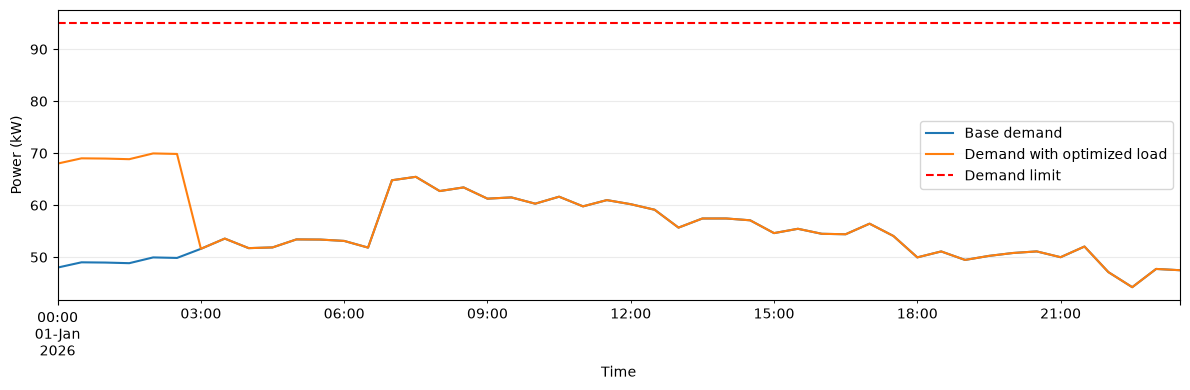

In [6]:
scheduled_kw = data["base_kw"].copy()
start_i = plan["start_index"]
slots = int(round(SHIFT_DURATION_HOURS * 60 / INTERVAL_MINUTES))
scheduled_kw.iloc[start_i:start_i + slots] += SHIFT_LOAD_KW
ax = data["base_kw"].plot(figsize=(12, 4), label="Base demand", linewidth=1.5)
scheduled_kw.plot(ax=ax, label="Demand with optimized load", linewidth=1.5)
ax.axhline(DEMAND_LIMIT_KW, color="red", linestyle="--", label="Demand limit")
ax.set_ylabel("Power (kW)")
ax.set_xlabel("Time")
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()